<a href="https://colab.research.google.com/github/931661716/GenAI-for-image-and-video/blob/main/GAN_In_Class_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thực hành: Mạng đối nghịch tạo sinh GAN
Trong bài này ta sẽ thực hành bài toán sinh ảnh chữ số viết tay MNIST bằng mạng GAN: trên lớp lập trình GAN cơ bản dùng các lớp kết nối đầy đủ, về nhà cải tiến thành DCGAN dùng tích chập.

**Lưu ý**: chạy notebook trên Google Colab với GPU (*Runtime → Change runtime type → T4 GPU*). Sinh viên lập trình vào các ô có dòng `# your code here`.

# 1. Cài đặt

Kiểm tra GPU

In [1]:
!nvidia-smi

Sat Oct 17 14:36:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Khai báo các thư viện cần thiết

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.utils import make_grid

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(2026)
print('Thiết bị:', device)

Thiết bị: cuda


Thiết lập các hằng số cho tập MNIST

In [3]:
width      = 28
height     = 28
channels   = 1
latent_dim = 100     # số chiều vectơ nhiễu đầu vào của Generator
batch_size = 64
epochs     = 30      # GAN cơ bản

# 2. Chuẩn bị dữ liệu

Tải tập dữ liệu MNIST. Ta chỉ dùng tập huấn luyện và **không dùng nhãn**. Các điểm ảnh được chuẩn hoá về miền giá trị $[-1, 1]$ cho khớp với hàm `tanh` ở lớp ra của Generator.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True,
                                          num_workers=2, drop_last=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 462kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.33MB/s]


Trực quan dữ liệu MNIST

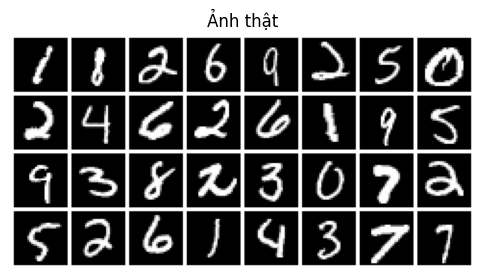

[1, 8, 2, 6, 9, 2, 5, 0, 2, 4, 6, 2, 6, 1, 9, 5, 9, 3, 8, 2, 3, 0, 7, 2, 5, 2, 6, 1, 4, 3, 7, 7]


In [5]:
def show_images(imgs, nrow=8, title=None):
    grid = make_grid(imgs.detach().cpu(), nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    if title:
        plt.title(title)
    plt.show()

images, labels = next(iter(trainloader))
show_images(images[:32], title='Ảnh thật')
print(labels[:32].tolist())

# 3. Generator

Lập trình mạng Generator:

*   Đầu vào là vectơ nhiễu ngẫu nhiên `latent_dim` = 100 chiều
*   Đầu ra là một ảnh giả kích thước `(1, 28, 28)` với giá trị điểm ảnh trong khoảng $[-1, 1]$

Các thông số của mạng như sau:

*   `Linear(100, 256)` → `LeakyReLU(0.2)` → `BatchNorm1d(256)`
*   `Linear(256, 512)` → `LeakyReLU(0.2)` → `BatchNorm1d(512)`
*   `Linear(512, 1024)` → `LeakyReLU(0.2)` → `BatchNorm1d(1024)`
*   `Linear(1024, 28*28)` → `Tanh()`
*   Đổi kích thước đầu ra thành `(N, 1, 28, 28)`

In [6]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        def block(in_f, out_f):
            # Linear -> LeakyReLU(0.2) -> BatchNorm1d
            return [nn.Linear(in_f, out_f), nn.LeakyReLU(0.2), nn.BatchNorm1d(out_f)]

        self.model = nn.Sequential(
            *block(latent_dim, 256),
            *block(256, 512),
            *block(512, 1024),
            nn.Linear(1024, channels * height * width),
            nn.Tanh(),                      # đưa giá trị điểm ảnh về [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)                                 # (N, 784)
        return img.view(z.size(0), channels, height, width) # (N, 1, 28, 28)


G = Generator().to(device)
print(G)

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=256, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=512, out_features=1024, bias=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): Linear(in_features=1024, out_features=784, bias=True)
    (10): Tanh()
  )
)


Kiểm tra

In [7]:
out = G(torch.randn(16, latent_dim, device=device))
print(out.shape)
assert out.shape == (16, 1, 28, 28) and out.min() >= -1 and out.max() <= 1
print('OK')

torch.Size([16, 1, 28, 28])
OK


# 4. Discriminator

Lập trình mạng Discriminator:

*   Đầu vào là một ảnh `(1, 28, 28)` (ảnh thật hoặc ảnh giả)
*   Đầu ra là xác suất ảnh đó là ảnh thật, giá trị trong khoảng $[0, 1]$

Các thông số của mạng như sau:

*   `Flatten()`
*   `Linear(784, 784)` → `LeakyReLU(0.2)`
*   `Linear(784, 392)` → `LeakyReLU(0.2)`
*   `Linear(392, 1)` → `Sigmoid()`

In [8]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),                                   # (N, 1, 28, 28) -> (N, 784)
            nn.Linear(channels * height * width, 784), nn.LeakyReLU(0.2),
            nn.Linear(784, 392), nn.LeakyReLU(0.2),
            nn.Linear(392, 1), nn.Sigmoid(),                # xác suất ảnh là thật
        )

    def forward(self, img):
        return self.model(img)                              # (N, 1)


D = Discriminator().to(device)
print(D)

Discriminator(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=784, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Linear(in_features=784, out_features=392, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Linear(in_features=392, out_features=1, bias=True)
    (6): Sigmoid()
  )
)


Kiểm tra

In [9]:
p = D(out)
print(p.shape)
assert p.shape == (16, 1) and (p >= 0).all() and (p <= 1).all()
print('OK')

torch.Size([16, 1])
OK


# 5. Huấn luyện GAN

**Công việc cần thực hiện**:

1.   Khai báo hàm mất mát `adversarial_loss` là `nn.BCELoss()` và hai bộ tối ưu Adam `optimizer_G`, `optimizer_D` với `lr=0.0002`, `betas=(0.5, 0.999)`
2.   Trong hàm `train_gan`, lập trình hàm mất mát của Generator và Discriminator:
     *   `g_loss`: Generator muốn Discriminator đoán ảnh giả là **thật** → so sánh `D(gen_imgs)` với nhãn `valid`
     *   `d_loss`: trung bình của loss trên ảnh thật (so với `valid`) và loss trên ảnh giả (so với `fake`). Với ảnh giả phải dùng `gen_imgs.detach()`

**Câu hỏi**: Vì sao khi tính `d_loss` phải dùng `gen_imgs.detach()`?

**Trả lời** – Vì sao dùng `gen_imgs.detach()` khi tính `d_loss`?

*   `gen_imgs = G(z)` vẫn còn nối với đồ thị tính toán của G. Nếu không `detach()`, lệnh `d_loss.backward()` sẽ lan gradient ngược qua cả G, tính gradient cho tham số G một cách **vô ích** (tốn bộ nhớ và thời gian), vì bước này chỉ cập nhật D (`optimizer_D.step()`).
*   Ngoài ra đồ thị của `gen_imgs` đã bị giải phóng sau `g_loss.backward()`; backward lần hai qua G sẽ báo lỗi *"Trying to backward through the graph a second time"*.
*   Về ý nghĩa: gradient của `d_loss` theo G có hướng **ngược** với mục tiêu của G (D muốn ảnh giả bị nhận là giả). `detach()` coi ảnh giả như dữ liệu đầu vào cố định, tách hẳn hai bước cập nhật của trò chơi đối nghịch.

In [10]:
adversarial_loss = nn.BCELoss()

optimizer_G = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [11]:
fixed_z = torch.randn(16, latent_dim, device=device)   # nhiễu cố định để theo dõi ảnh sinh qua các epoch

def train_gan(G, D, optimizer_G, optimizer_D, epochs):
    losses_G, losses_D, samples = [], [], []
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        for imgs, _ in trainloader:
            real_imgs = imgs.to(device)
            valid = torch.ones(imgs.size(0), 1, device=device)    # nhãn ảnh thật
            fake = torch.zeros(imgs.size(0), 1, device=device)    # nhãn ảnh giả

            # -----------------
            #  Train Generator
            # -----------------
            optimizer_G.zero_grad()
            z = torch.randn(imgs.size(0), latent_dim, device=device)
            gen_imgs = G(z)

            # G muốn D đoán ảnh giả là THẬT -> so với nhãn valid
            g_loss = adversarial_loss(D(gen_imgs), valid)

            g_loss.backward()
            optimizer_G.step()

            # ---------------------
            #  Train Discriminator
            # ---------------------
            optimizer_D.zero_grad()

            # D muốn đoán ảnh thật là thật (valid) và ảnh giả là giả (fake)
            real_loss = adversarial_loss(D(real_imgs), valid)
            fake_loss = adversarial_loss(D(gen_imgs.detach()), fake)   # detach: không lan gradient về G
            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            optimizer_D.step()

        losses_G.append(g_loss.item())
        losses_D.append(d_loss.item())
        G.eval()
        with torch.no_grad():
            samples.append(G(fixed_z).cpu())
        G.train()
        print('[Epoch %d/%d] [D loss: %.4f] [G loss: %.4f] %.0fs'
              % (epoch, epochs, d_loss.item(), g_loss.item(), time.time() - t0))
    return losses_G, losses_D, samples


losses_G, losses_D, samples = train_gan(G, D, optimizer_G, optimizer_D, epochs)

[Epoch 1/30] [D loss: 0.6175] [G loss: 0.4869] 17s
[Epoch 2/30] [D loss: 0.5411] [G loss: 0.9730] 16s
[Epoch 3/30] [D loss: 0.5732] [G loss: 1.0718] 17s
[Epoch 4/30] [D loss: 0.5939] [G loss: 0.8203] 16s
[Epoch 5/30] [D loss: 0.6118] [G loss: 1.1383] 16s
[Epoch 6/30] [D loss: 0.6707] [G loss: 0.5287] 16s
[Epoch 7/30] [D loss: 0.7094] [G loss: 1.2232] 16s
[Epoch 8/30] [D loss: 0.6184] [G loss: 0.9690] 16s
[Epoch 9/30] [D loss: 0.6168] [G loss: 0.8968] 16s
[Epoch 10/30] [D loss: 0.6519] [G loss: 0.9174] 16s
[Epoch 11/30] [D loss: 0.6535] [G loss: 0.9086] 16s
[Epoch 12/30] [D loss: 0.6761] [G loss: 0.8465] 16s
[Epoch 13/30] [D loss: 0.6172] [G loss: 0.8810] 16s
[Epoch 14/30] [D loss: 0.6406] [G loss: 1.0877] 16s
[Epoch 15/30] [D loss: 0.6244] [G loss: 1.0308] 16s
[Epoch 16/30] [D loss: 0.6506] [G loss: 0.5800] 16s
[Epoch 17/30] [D loss: 0.6550] [G loss: 0.6277] 16s
[Epoch 18/30] [D loss: 0.6175] [G loss: 1.2168] 16s
[Epoch 19/30] [D loss: 0.6125] [G loss: 0.9856] 16s
[Epoch 20/30] [D loss

# 6. Đánh giá kết quả

Vẽ đồ thị hàm loss huấn luyện

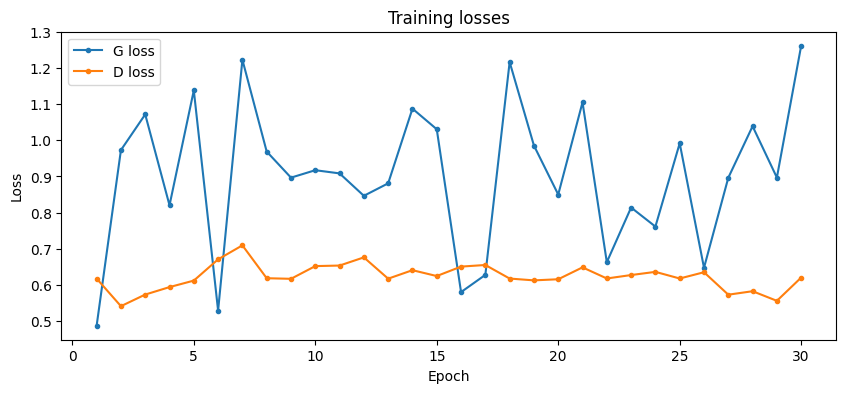

In [12]:
def plot_losses(losses_G, losses_D, title='Training losses'):
    ep = range(1, len(losses_G) + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(ep, losses_G, 'o-', ms=3, label='G loss')
    plt.plot(ep, losses_D, 'o-', ms=3, label='D loss')
    plt.title(title); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
    plt.show()

plot_losses(losses_G, losses_D)

Trực quan ảnh sinh ra từ cùng một bộ nhiễu cố định qua các epoch

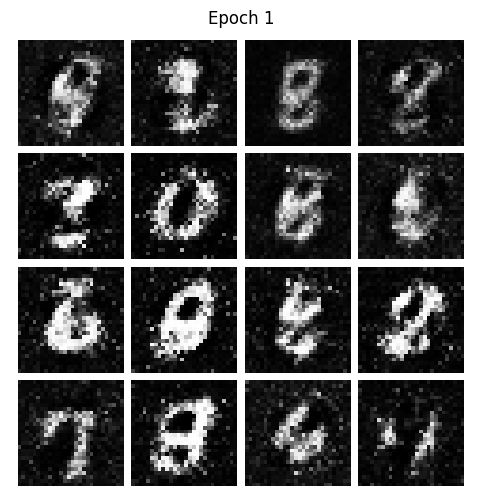

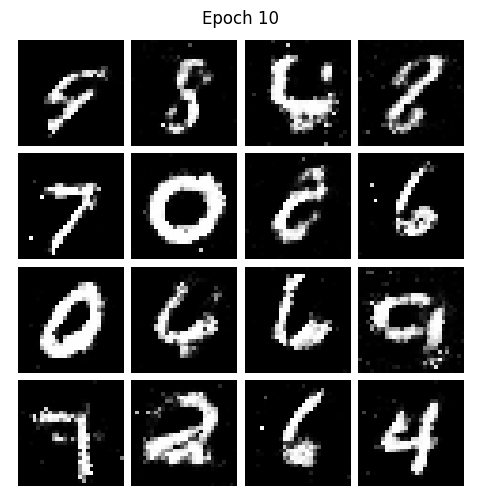

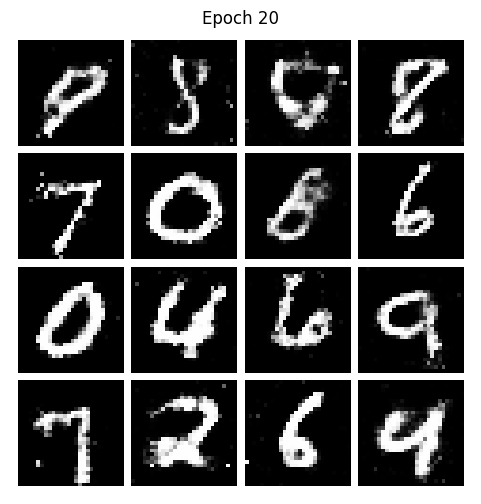

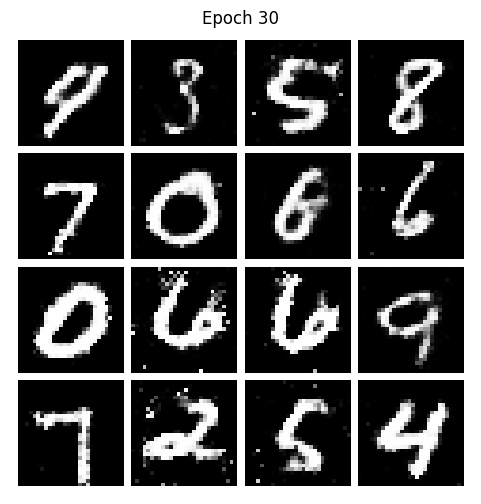

In [13]:
for i in np.unique(np.linspace(0, len(samples) - 1, 4).astype(int)):
    show_images(samples[i], nrow=4, title='Epoch %d' % (i + 1))

Sinh ảnh mới từ nhiễu ngẫu nhiên bằng Generator đã huấn luyện

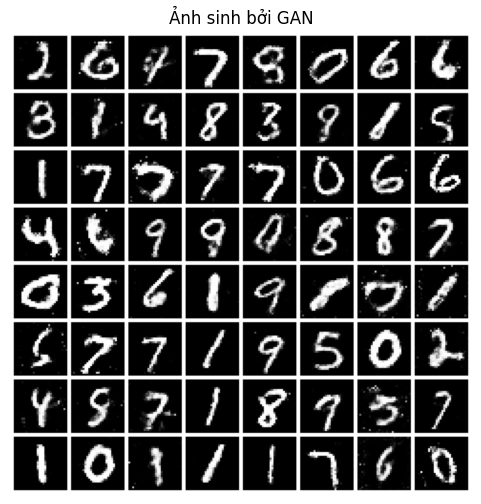

In [14]:
G.eval()
with torch.no_grad():
    gen_images = G(torch.randn(64, latent_dim, device=device))
show_images(gen_images, nrow=8, title='Ảnh sinh bởi GAN')

**Câu hỏi**:

1.   Loss của G có giảm đều như khi huấn luyện mạng phân loại không? Giải thích.
2.   Quan sát ảnh sinh ra: có chữ số nào xuất hiện nhiều bất thường hoặc không xuất hiện không? Hiện tượng đó gọi là gì?

*Trả lời*:

1.   **Không.** Trong mạng phân loại, loss đo khoảng cách tới một mục tiêu cố định nên giảm dần. Trong GAN, G và D chơi trò chơi minimax: loss của G phụ thuộc vào D, mà D liên tục thay đổi (mạnh lên) để đánh bại G. Khi G tốt hơn thì D bị đánh lừa (g_loss giảm), sau đó D học lại khiến g_loss tăng… Vì vậy đồ thị loss **dao động / tăng nhẹ**, không giảm đều, và giá trị loss không phản ánh trực tiếp chất lượng ảnh — phải nhìn ảnh sinh ra để đánh giá. Điểm cân bằng lý tưởng là $D(x) = 0.5$, khi đó mỗi loss BCE ≈ $\ln 2 \approx 0.69$.
2.   Thường thấy một số chữ số (ví dụ 1, 7, 9) xuất hiện nhiều bất thường, trong khi số khác (ví dụ 2, 8) hiếm hoặc vắng mặt; nhiều ảnh trông gần giống nhau. Hiện tượng này gọi là **sụp đổ chế độ (mode collapse)**: G chỉ học một vài "mode" của phân phối dữ liệu đủ để đánh lừa D, thay vì bao phủ toàn bộ phân phối.

# 7. Bài tập về nhà: Mô hình sinh DCGAN

Thay các lớp kết nối đầy đủ bằng các lớp tích chập. Dùng lại hàm `train_gan` ở phần 5.

*Lưu ý*: Generator cần có `BatchNorm` như mô tả dưới đây. Nếu bỏ BatchNorm, Discriminator thắng áp đảo ngay từ những batch đầu tiên ($D(x) \approx 1$, $D(G(z)) \approx 0$, loss của G tăng liên tục) và Generator không học được.

## 7.1. Generator

*   Đầu vào là vectơ ngẫu nhiên 100 chiều
*   Đầu ra là một ảnh giả `(1, 28, 28)` với giá trị điểm ảnh trong khoảng $[-1, 1]$

Các thông số của mạng như sau:

*   `Linear(100, 128*7*7)` → `BatchNorm1d(128*7*7)` → `LeakyReLU(0.2)`
*   Đổi kích thước thành `(N, 128, 7, 7)`
*   `Upsample(scale_factor=2)` → `Conv2d(128, 64, kernel_size=5, padding=2)` → `BatchNorm2d(64)` → `LeakyReLU(0.2)` : `(N, 64, 14, 14)`
*   `Upsample(scale_factor=2)` → `Conv2d(64, 1, kernel_size=5, padding=2)` → `Tanh()` : `(N, 1, 28, 28)`

In [15]:
class DCGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 128 * 7 * 7),
            nn.BatchNorm1d(128 * 7 * 7),
            nn.LeakyReLU(0.2),
        )
        self.conv = nn.Sequential(
            nn.Upsample(scale_factor=2),                         # (N,128,7,7)  -> (N,128,14,14)
            nn.Conv2d(128, 64, kernel_size=5, padding=2),        #              -> (N,64,14,14)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Upsample(scale_factor=2),                         #              -> (N,64,28,28)
            nn.Conv2d(64, channels, kernel_size=5, padding=2),   #              -> (N,1,28,28)
            nn.Tanh(),
        )

    def forward(self, z):
        x = self.fc(z).view(z.size(0), 128, 7, 7)
        return self.conv(x)


G_dc = DCGenerator().to(device)
print(G_dc(torch.randn(16, latent_dim, device=device)).shape)   # kết quả đúng: torch.Size([16, 1, 28, 28])

torch.Size([16, 1, 28, 28])


## 7.2. Discriminator

*   Đầu vào là một ảnh `(1, 28, 28)`
*   Đầu ra là xác suất ảnh là ảnh thật, giá trị trong khoảng $[0, 1]$

Các thông số của mạng như sau (`dropout_rate = 0.3`):

*   `Conv2d(1, 64, kernel_size=5, stride=2, padding=2)` → `LeakyReLU(0.2)` → `Dropout(0.3)` : `(N, 64, 14, 14)`
*   `Conv2d(64, 128, kernel_size=5, stride=2, padding=2)` → `LeakyReLU(0.2)` → `Dropout(0.3)` : `(N, 128, 7, 7)`
*   `Flatten()` → `Linear(128*7*7, 1)` → `Sigmoid()`

In [16]:
class DCDiscriminator(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(channels, 64, kernel_size=5, stride=2, padding=2),   # -> (N,64,14,14)
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Conv2d(64, 128, kernel_size=5, stride=2, padding=2),        # -> (N,128,7,7)
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout_rate),
            nn.Flatten(),                                                  # -> (N,6272)
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid(),
        )

    def forward(self, img):
        return self.model(img)


D_dc = DCDiscriminator().to(device)
print(D_dc(torch.randn(16, 1, 28, 28, device=device)).shape)    # kết quả đúng: torch.Size([16, 1])

torch.Size([16, 1])


## 7.3. Huấn luyện DCGAN

Khai báo hai bộ tối ưu Adam cho `G_dc`, `D_dc` (cùng tham số như phần 5), huấn luyện bằng hàm `train_gan` trong `epochs_dc = 15` epoch và lưu kết quả vào `losses_G_dc, losses_D_dc, samples_dc`.

In [17]:
epochs_dc = 15

optimizer_G_dc = optim.Adam(G_dc.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D_dc = optim.Adam(D_dc.parameters(), lr=0.0002, betas=(0.5, 0.999))

losses_G_dc, losses_D_dc, samples_dc = train_gan(G_dc, D_dc, optimizer_G_dc, optimizer_D_dc, epochs_dc)

[Epoch 1/15] [D loss: 0.6330] [G loss: 1.0228] 17s
[Epoch 2/15] [D loss: 0.5774] [G loss: 1.0414] 17s
[Epoch 3/15] [D loss: 0.5647] [G loss: 0.9883] 17s
[Epoch 4/15] [D loss: 0.5932] [G loss: 0.7797] 18s
[Epoch 5/15] [D loss: 0.5895] [G loss: 0.8541] 17s
[Epoch 6/15] [D loss: 0.5531] [G loss: 1.0665] 17s
[Epoch 7/15] [D loss: 0.6140] [G loss: 1.0900] 18s
[Epoch 8/15] [D loss: 0.5476] [G loss: 1.0199] 18s
[Epoch 9/15] [D loss: 0.7228] [G loss: 0.8801] 18s
[Epoch 10/15] [D loss: 0.5380] [G loss: 1.1721] 18s
[Epoch 11/15] [D loss: 0.5449] [G loss: 1.0047] 18s
[Epoch 12/15] [D loss: 0.6001] [G loss: 1.1212] 18s
[Epoch 13/15] [D loss: 0.5115] [G loss: 1.0987] 18s
[Epoch 14/15] [D loss: 0.6114] [G loss: 0.9674] 18s
[Epoch 15/15] [D loss: 0.5503] [G loss: 0.9540] 18s


## 7.4. Đánh giá

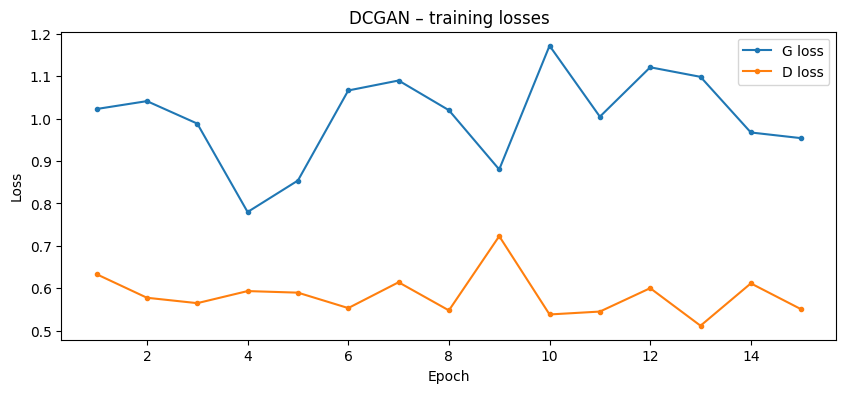

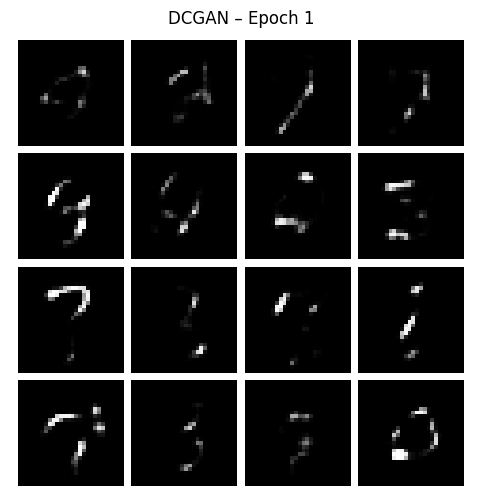

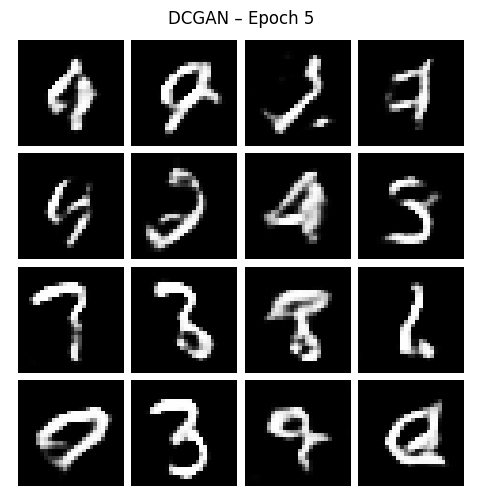

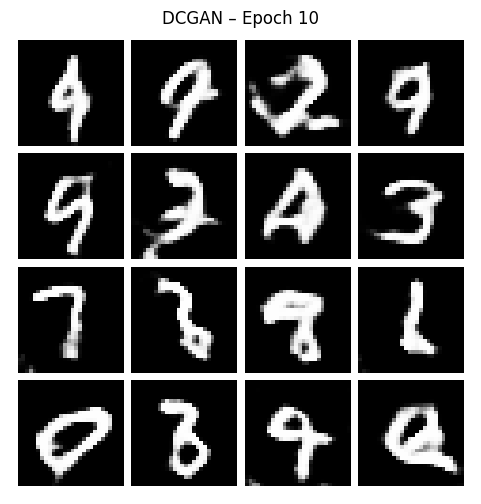

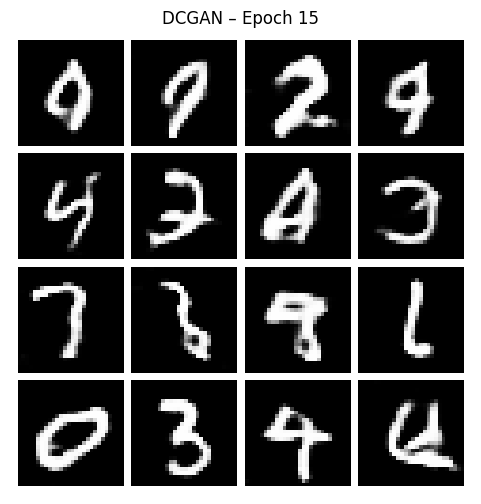

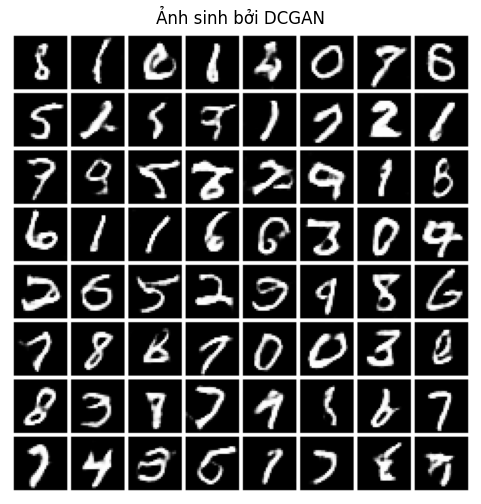

In [18]:
plot_losses(losses_G_dc, losses_D_dc, 'DCGAN – training losses')
for i in np.unique(np.linspace(0, len(samples_dc) - 1, 4).astype(int)):
    show_images(samples_dc[i], nrow=4, title='DCGAN – Epoch %d' % (i + 1))

G_dc.eval()
with torch.no_grad():
    show_images(G_dc(torch.randn(64, latent_dim, device=device)), nrow=8, title='Ảnh sinh bởi DCGAN')

**Câu hỏi**:

1.   So sánh số tham số và chất lượng ảnh sinh của GAN cơ bản và DCGAN. Giải thích vì sao DCGAN cho nét chữ liền mạch hơn.
2.   Thay `Upsample` + `Conv2d` trong Generator bằng `ConvTranspose2d(kernel_size=4, stride=2, padding=1)`. Kết quả thay đổi thế nào?
3.   Thay MNIST bằng Fashion-MNIST (`torchvision.datasets.FashionMNIST`) và nhận xét.

*Trả lời*:

*Trả lời*:

1.   **Số tham số** (tính tay, có thể kiểm tra bằng ô code bên dưới):

     | Mô hình | Generator | Discriminator | Tổng |
     |---|---|---|---|
     | GAN cơ bản | 1 489 936 | 923 553 | ≈ 2,41 triệu |
     | DCGAN | 852 609 | 212 865 | ≈ 1,07 triệu |

     DCGAN dùng ít hơn khoảng một nửa số tham số nhưng ảnh sinh **sắc nét hơn, nét chữ liền mạch, ít nhiễu lấm tấm** và hội tụ nhanh hơn (15 epoch so với 30). Lý do: lớp tích chập có **tính cục bộ** (mỗi điểm ảnh ra được tính từ vùng lân cận 5×5) và **chia sẻ trọng số** trên toàn ảnh, nên mạng mã hoá sẵn giả định "điểm ảnh gần nhau thì liên quan với nhau" — đúng với nét bút liên tục. GAN cơ bản sinh 784 điểm ảnh độc lập qua lớp `Linear`, không biết điểm nào nằm cạnh điểm nào, nên dễ tạo nhiễu rời rạc và nét đứt. Ở D, tích chập trích các đặc trưng không gian (cạnh, nét cong), nên đưa ra gradient có ý nghĩa hơn cho G.
2.   `ConvTranspose2d(kernel_size=4, stride=2, padding=1)` cũng tăng gấp đôi kích thước (7→14→28), số tham số ít hơn một chút (kernel 4×4 thay vì 5×5: G còn 778 305 tham số). Mạng vẫn học được và thường hội tụ nhanh tương đương, nhưng ảnh dễ xuất hiện **hiện tượng bàn cờ (checkerboard artifacts)** – các vân ô vuông nhỏ – do kernel chồng lấn không đều khi stride=2. `Upsample` + `Conv2d` tránh được điều này nên ảnh mịn hơn. (Xem ô thí nghiệm bên dưới.)
3.   Fashion-MNIST (áo, quần, giày, túi…) khó hơn MNIST: hình dạng đa dạng hơn, có vân vải và chi tiết bên trong. GAN cơ bản sinh ảnh mờ, nhiễu, nhiều ảnh lẫn lộn giữa các lớp; DCGAN vẫn sinh ra được hình dáng tổng thể rõ ràng (áo, giày, quần) nhưng chi tiết (hoa văn, logo, quai túi) còn mờ, và mode collapse có thể rõ hơn. Cần nhiều epoch hơn hoặc mạng lớn hơn để có kết quả tốt. (Xem ô thí nghiệm bên dưới.)

### Thí nghiệm phục vụ câu hỏi

In [19]:
# Câu 1: đếm số tham số
count = lambda m: sum(p.numel() for p in m.parameters())
print('GAN   : G = %d, D = %d, tổng = %d' % (count(G), count(D), count(G) + count(D)))
print('DCGAN : G = %d, D = %d, tổng = %d' % (count(G_dc), count(D_dc), count(G_dc) + count(D_dc)))

GAN   : G = 1489936, D = 923553, tổng = 2413489
DCGAN : G = 852609, D = 212865, tổng = 1065474


[Epoch 1/15] [D loss: 0.6161] [G loss: 0.5806] 16s
[Epoch 2/15] [D loss: 0.4368] [G loss: 1.1875] 16s
[Epoch 3/15] [D loss: 0.5958] [G loss: 1.0897] 16s
[Epoch 4/15] [D loss: 0.4530] [G loss: 1.2275] 16s
[Epoch 5/15] [D loss: 0.5666] [G loss: 1.1742] 16s
[Epoch 6/15] [D loss: 0.5380] [G loss: 1.1025] 16s
[Epoch 7/15] [D loss: 0.5927] [G loss: 0.8007] 16s
[Epoch 8/15] [D loss: 0.5892] [G loss: 1.2101] 16s
[Epoch 9/15] [D loss: 0.5893] [G loss: 1.2232] 16s
[Epoch 10/15] [D loss: 0.4881] [G loss: 1.1137] 16s
[Epoch 11/15] [D loss: 0.5654] [G loss: 1.5434] 17s
[Epoch 12/15] [D loss: 0.5751] [G loss: 1.0957] 16s
[Epoch 13/15] [D loss: 0.6091] [G loss: 1.1086] 17s
[Epoch 14/15] [D loss: 0.4518] [G loss: 1.3340] 16s
[Epoch 15/15] [D loss: 0.6044] [G loss: 0.9146] 16s


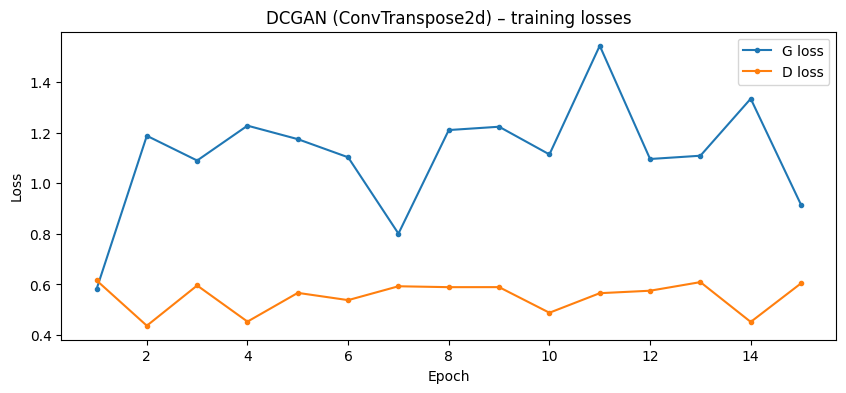

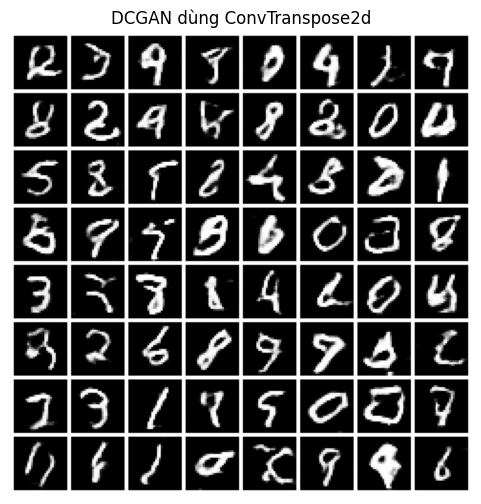

In [20]:
# Câu 2: Generator dùng ConvTranspose2d thay cho Upsample + Conv2d
class DCGeneratorT(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(latent_dim, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.LeakyReLU(0.2))
        self.conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),        # 7 -> 14
            nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, channels, kernel_size=4, stride=2, padding=1),   # 14 -> 28
            nn.Tanh(),
        )

    def forward(self, z):
        return self.conv(self.fc(z).view(z.size(0), 128, 7, 7))

G_t, D_t = DCGeneratorT().to(device), DCDiscriminator().to(device)
opt_G_t = optim.Adam(G_t.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D_t = optim.Adam(D_t.parameters(), lr=0.0002, betas=(0.5, 0.999))
losses_G_t, losses_D_t, samples_t = train_gan(G_t, D_t, opt_G_t, opt_D_t, epochs_dc)
plot_losses(losses_G_t, losses_D_t, 'DCGAN (ConvTranspose2d) – training losses')
G_t.eval()
with torch.no_grad():
    show_images(G_t(torch.randn(64, latent_dim, device=device)), nrow=8, title='DCGAN dùng ConvTranspose2d')

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.9MB/s]


[Epoch 1/15] [D loss: 0.4396] [G loss: 1.5497] 18s
[Epoch 2/15] [D loss: 0.4865] [G loss: 1.1638] 18s
[Epoch 3/15] [D loss: 0.5593] [G loss: 1.3466] 18s
[Epoch 4/15] [D loss: 0.5577] [G loss: 1.1007] 18s
[Epoch 5/15] [D loss: 0.5475] [G loss: 1.0780] 18s
[Epoch 6/15] [D loss: 0.5624] [G loss: 1.0160] 18s
[Epoch 7/15] [D loss: 0.5191] [G loss: 1.1019] 18s
[Epoch 8/15] [D loss: 0.5386] [G loss: 0.9335] 18s
[Epoch 9/15] [D loss: 0.5494] [G loss: 1.0359] 18s
[Epoch 10/15] [D loss: 0.4852] [G loss: 1.1987] 18s
[Epoch 11/15] [D loss: 0.4947] [G loss: 1.2377] 18s
[Epoch 12/15] [D loss: 0.6358] [G loss: 1.2221] 18s
[Epoch 13/15] [D loss: 0.4916] [G loss: 1.1381] 18s
[Epoch 14/15] [D loss: 0.5291] [G loss: 1.4032] 18s
[Epoch 15/15] [D loss: 0.4808] [G loss: 1.3542] 18s


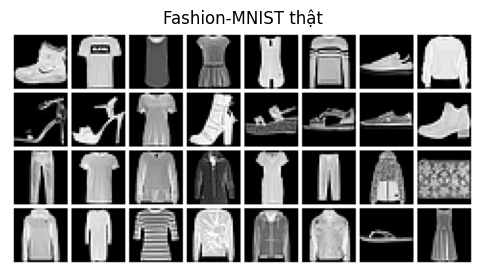

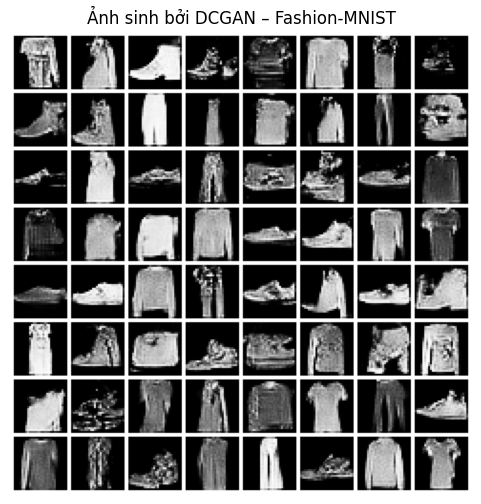

In [21]:
# Câu 3: huấn luyện DCGAN trên Fashion-MNIST
# train_gan dùng biến toàn cục trainloader nên ta gán lại trainloader rồi khôi phục sau đó
mnist_loader = trainloader
fashion_set = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(fashion_set, batch_size=batch_size, shuffle=True,
                                          num_workers=2, drop_last=True)

G_f, D_f = DCGenerator().to(device), DCDiscriminator().to(device)
opt_G_f = optim.Adam(G_f.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D_f = optim.Adam(D_f.parameters(), lr=0.0002, betas=(0.5, 0.999))
losses_G_f, losses_D_f, samples_f = train_gan(G_f, D_f, opt_G_f, opt_D_f, epochs_dc)
trainloader = mnist_loader

show_images(next(iter(torch.utils.data.DataLoader(fashion_set, batch_size=32)))[0], title='Fashion-MNIST thật')
G_f.eval()
with torch.no_grad():
    show_images(G_f(torch.randn(64, latent_dim, device=device)), nrow=8, title='Ảnh sinh bởi DCGAN – Fashion-MNIST')